# In-Context Learning, Part 2: Can a Tabular Foundation Model Learn Cancer Biology From a Few Examples?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/in-context-learning/03_icl_for_biology_tabpfn.ipynb)

Part 1a trained a tiny transformer on many random tasks until its forward pass *was* a learning algorithm. **TabPFN** is that idea at full scale for tables. It's a transformer pretrained on millions of **synthetic** datasets drawn from a prior over causal models. Given labelled rows in its context, it predicts new rows in a single forward pass: no training, no tuning. Its authors report state-of-the-art accuracy on small tabular benchmarks.

Biology is full of small tables. A new cancer type might have a dozen screened cell lines, a new assay a few dozen samples. So the question is practical: **when labelled cell lines are scarce, does an in-context learner predict cancer gene dependencies better than standard methods?**

We tested that on the DepMap CRISPR screens, with everything **pre-registered** (hypotheses, genes, features, model settings) before any model saw the data, and a final **prospective** test on cell lines screened after the data release.

**What you'll learn**

1. What TabPFN is and why it's an in-context learner
2. How to set up a fair comparison: same features, same context lines, fixed settings, pre-registration
3. The learning curve: how accuracy grows with the number of labelled cell lines
4. Adapting to a new cancer type from 8 examples
5. A prospective test on new cell lines and a new CRISPR system
6. How to report a result that didn't go the way you predicted

**Runtime:** seconds. The notebook reads the recorded results (2,704 model fits, about 4 hours on a laptop CPU), so it needs no data download and no GPU. Section 8 shows how to re-run it.

> 🎬 *Video walkthrough: coming soon.*

*TabPFN: Hollmann et al. (2025), "Accurate predictions on small data with a tabular foundation model", Nature. This notebook uses the TabPFN v2 weights under the Prior Labs License 1.1 (Apache 2.0 with attribution). Built with TabPFN.*

## 0. Setup

In [1]:
import os, sys, json, hashlib
if "google.colab" in sys.modules and not os.path.exists("icl_bio"):
    !git clone -q --depth 1 https://github.com/nathanmaulding/tutorial-projects.git
    %cd tutorial-projects/in-context-learning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from icl_bio import analysis as A

plt.rcParams.update({"figure.figsize": (7.5, 4.3), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
COLORS = {"TabPFN (in-context)": "#2a78d6", "random forest": "#eb6834", "ridge regression": "#1baf7a"}
pd.set_option("display.precision", 3)
df = A.load()
print(f"{len(df):,} recorded predictions;", df[df.method == "tabpfn"].shape[0], "TabPFN fits")

2,704 recorded predictions; 676 TabPFN fits


## 1. TabPFN: in-context learning for tables

In Part 1a the model's training tasks were random linear functions, so it learned to do linear regression in context. TabPFN's training tasks are random *datasets*: thousands of features generated by random causal graphs, with nonlinear relationships, noise and irrelevant columns. To predict well across all of them it has to infer, from the context rows, which features matter and how. That's approximate Bayesian inference over the prior's datasets, done in one forward pass.

Two properties matter here:
- **Nothing to fit.** The labelled rows *are* the "training"; the weights never change. Prediction is one pass over context plus test rows.
- **It has never seen real data.** Pretraining was purely synthetic, so it can't have memorised DepMap. That makes it a clean test of whether its built-in prior suits biology.

## 2. The task and a fair comparison

**Data:** DepMap 24Q4 CRISPR knockout screens (Broad Avana library), split before anything else into a *discovery* pool (618 cell lines with expression data) and a *held-out* test set (413 lines). These are the same splits as the agentic-AI-for-science tutorial.

**Targets:** 20 genes chosen by a rule on discovery lines only: the most variable *selective* dependencies (needed by 5–50% of lines, not broadly essential). We also report 6 paralog targets from the agentic project.

**Features:** RNA expression. For each target, the 50 genes whose expression correlates most with it, computed **on the context lines only**, so the test lines never influence which features are used. Every method gets exactly the same features and the same context lines.

**Methods:** TabPFN (v2, 2 ensemble members); ridge regression (penalty chosen by internal cross-validation); random forest (300 trees). The metric is the Pearson correlation between predicted and measured gene effect on the test lines.

Everything above, plus four hypotheses and our predictions, was **frozen in a pre-registration** before any model was fitted. Its SHA-256 fingerprint is checked here:

In [2]:
text = open("runs/part2/preregistration.json").read()
assert hashlib.sha256(text.encode()).hexdigest() == open("runs/part2/preregistration.sha256").read().split()[0]
pre = json.loads(text)
print("pre-registration unedited; written", pre["written_utc"])
print("targets:", ", ".join(pre["primary_targets"]))
for h, t in pre["hypotheses"].items():
    print(f"\n{h}: {t}")
print("\nClarification made before any results:", json.load(open("runs/part2/clarifications.json"))["clarifications"][0]["text"])

pre-registration unedited; written 2026-11-14T16:12:56+00:00
targets: TYMS, KEAP1, CBFB, NXT1, HNF1B, TSC2, EP300, SOX10, TADA1, NF2, TAF5L, ITGAV, STAG2, NMNAT1, AMBRA1, PAXIP1, MEN1, IRF4, KLF5, EFR3A

H1 (primary): Few-shot advantage: at k = 16 and k = 64, mean over the 20 primary targets of r(TabPFN) - r(baseline) > 0 for baseline = ridge and = random forest. 4 comparisons; each tested with a gene-level bootstrap 98.75% interval (Bonferroni over the 4); supported if the interval excludes 0.

H2: At k = 626 (all discovery lines), TabPFN vs ridge and vs random forest: two-sided, reported with 95% intervals.

H3: Adapting to a cancer type: the gain from 0 to 8 in-lineage examples (mean over lineages and targets) is larger for TabPFN than for ridge. Secondary; 95% interval.

H4: Prospective: on new Cas12 lines, TabPFN vs ridge and vs random forest over eligible targets; two-sided, 95% intervals; reported whatever the number of eligible targets.

Clarification made before any results: C

## 3. Experiment 1: the learning curve

For each target we give each method $k$ = 16, 64, 256 or all 618 discovery lines as context (3 random draws for the smaller sizes), and predict all 413 held-out lines.

> ⏸️ **Pause and predict:** TabPFN was built for small data, and its prior should act like regularisation when examples are scarce. Where on the curve do you expect it to beat random forest: at 16 lines, at 618, or nowhere?

In [3]:
curve = A.curve_table(df)
curve

,genes,TabPFN (in-context),random forest,ridge regression
k,,,,
16.0,20,0.251,0.262,0.188
64.0,20,0.359,0.387,0.342
256.0,20,0.472,0.480,0.466
626.0,20,0.523,0.519,0.500


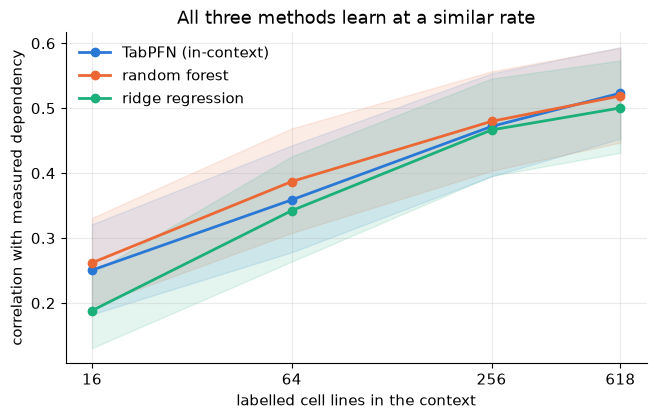

In [4]:
g = A.per_gene(df[(df.experiment == "E1_curve") & (df.set == "primary")], ["k"])
fig, ax = plt.subplots()
rng = np.random.default_rng(0)
for m, name in [("tabpfn", "TabPFN (in-context)"), ("random_forest", "random forest"), ("ridge", "ridge regression")]:
    ks, mean, lo, hi = [], [], [], []
    for k, sub in g[m].groupby(level="k"):
        v = sub.to_numpy(); b = v[rng.integers(0, len(v), (3000, len(v)))].mean(1)
        ks.append(k); mean.append(v.mean()); lo.append(np.quantile(b, 0.025)); hi.append(np.quantile(b, 0.975))
    ax.plot(ks, mean, "-o", color=COLORS[name], lw=2, label=name)
    ax.fill_between(ks, lo, hi, color=COLORS[name], alpha=0.12)
ax.set(xscale="log", xlabel="labelled cell lines in the context", ylabel="correlation with measured dependency",
       title="All three methods learn at a similar rate")
ax.set_xticks([16, 64, 256, 626], ["16", "64", "256", "618"])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.legend(frameon=False); plt.show()

**What just happened.** Every method improves steadily with more cell lines, from a correlation around 0.2–0.26 with 16 lines to about 0.5 with all 618. The three curves are close together; the bands are 95% intervals over genes. The question is whether the small gaps are real, which is what the pre-registered tests decide.

## 4. The pre-registered verdicts

Each comparison is the mean, over the 20 genes, of TabPFN's correlation minus the baseline's, with a bootstrap interval over genes. The four few-shot comparisons (H1) use 98.75% intervals, a Bonferroni correction for testing four things at once.

In [5]:
hyp = A.hypotheses(df)
hyp

,hypothesis,comparison,units,mean difference,interval level,interval,excludes 0
0,H1,"TabPFN - ridge regression, k = 16",20,0.062,98.75%,"(0.031, 0.106)",True
1,H1,"TabPFN - random forest, k = 16",20,-0.011,98.75%,"(-0.036, 0.011)",False
2,H1,"TabPFN - ridge regression, k = 64",20,0.017,98.75%,"(-0.011, 0.044)",False
3,H1,"TabPFN - random forest, k = 64",20,-0.028,98.75%,"(-0.042, -0.015)",True
4,H2,"TabPFN - ridge regression, k = 626",20,0.023,95.00%,"(0.011, 0.038)",True
5,H2,"TabPFN - random forest, k = 626",20,0.004,95.00%,"(-0.003, 0.012)",False
6,H3,gain from 8 in-lineage examples: TabPFN - ridge,100,0.012,95.00%,"(0.003, 0.022)",True
7,H3 (detail),"gain from 8 in-lineage examples, TabPFN (in-co...",100,0.018,95.00%,"(0.005, 0.032)",True
8,H3 (detail),"gain from 8 in-lineage examples, ridge regression",100,0.006,95.00%,"(-0.005, 0.016)",False
9,H3 (detail),"gain from 8 in-lineage examples, random forest",100,0.015,95.00%,"(0.004, 0.027)",True


| Hypothesis | Our prediction | Result |
|---|---|---|
| **H1** few-shot advantage at 16 and 64 lines, over ridge *and* random forest | TabPFN ahead | **Not supported.** It beats ridge at 16 lines (+0.06), but **random forest is better than TabPFN at 64 lines** (−0.03); the other two comparisons are ties |
| **H2** all 618 lines | close to random forest | **As predicted.** A tie with random forest (+0.004), ahead of ridge (+0.02) |
| **H3** gain from 8 examples of a new cancer type | uncertain | Supported but tiny (section 5) |
| **H4** prospective test | the H2 ordering, lower correlations | **As predicted** (section 6) |

**The prediction we cared most about failed.** An in-context learner built for small data did *not* beat a random forest when data were small. That's worth stating as plainly as a success: it's the result a team deciding whether to adopt the method needs.

### A second metric tells a sharper story

Correlation rewards getting the *ranking* of cell lines right. Out-of-sample $R^2$ also asks whether the predicted *values* are on the right scale (0 means no better than predicting the context average).

In [6]:
A.curve_table(df, metric="r2_oos")

,genes,TabPFN (in-context),random forest,ridge regression,context mean
k,,,,,
16.0,20,-0.035,0.073,-0.793,-2.323e-09
64.0,20,-0.004,0.165,-0.385,9.846e-10
256.0,20,0.240,0.255,0.236,3.403e-10
626.0,20,0.298,0.293,0.273,3.610e-10


With 16 or 64 lines, TabPFN's $R^2$ is about zero and ridge's is strongly negative, while random forest's is positive. So at small sizes TabPFN ranks cell lines about as well as random forest, but its predicted values are no better calibrated than the average. With 256 or more lines all three converge. This was a secondary metric, so treat it as a pointer rather than a finding.

## 5. Experiment 2: adapting to a new cancer type

Here the context holds discovery lines from *other* cancer types, plus 0 or 8 lines of the target type (3 draws). We predict the target type's held-out lines, for the 5 largest lineages. The question: how much do 8 in-lineage examples help each method?

In [7]:
lin = A.lineage_table(df)
lin

TabPFN (in-context)  random forest  ridge regression
lineage           k                                                        
CNS/Brain         0.0                0.305          0.280             0.304
                  8.0                0.323          0.297             0.316
Esophagus/Stomach 0.0                0.257          0.269             0.280
                  8.0                0.263          0.270             0.278
Lung              0.0                0.250          0.277             0.282
                  8.0                0.266          0.288             0.290
Lymphoid          0.0                0.105          0.097             0.080
                  8.0                0.105          0.114             0.078
Skin              0.0                0.295          0.275             0.287
                  8.0                0.344          0.305             0.300

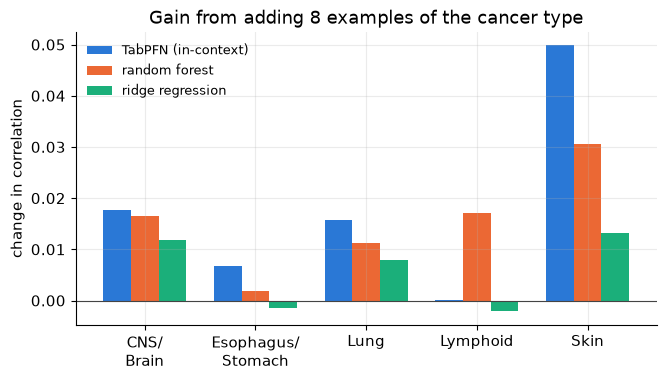

In [8]:
gl = A.per_gene(df[df.experiment == "E2_lineage"], ["lineage", "k"])
gain = (gl.xs(8, level="k") - gl.xs(0, level="k")).groupby(level="lineage").mean()
gain = gain[["tabpfn", "random_forest", "ridge"]].rename(columns=A.NAMES)
gain.index = [i.replace("/", "/\n") for i in gain.index]
ax = gain.plot.bar(color=[COLORS[c] for c in gain.columns], figsize=(7.5, 3.8), rot=0, width=0.75)
ax.axhline(0, color="#444", lw=0.8)
ax.set(ylabel="change in correlation", xlabel="", title="Gain from adding 8 examples of the cancer type")
ax.legend(frameon=False, fontsize=9); plt.show()

**What just happened.** Eight in-lineage examples help a little, mostly in skin cancers (where TabPFN gains about 0.05) and barely elsewhere. TabPFN's average gain (+0.018) is larger than ridge's (+0.006), so H3 is technically supported. But random forest gains about as much (+0.015), and the effects are small next to the gap between cancer types: lymphoid cancers stay hard (correlation about 0.1) whatever the method. Eight examples aren't enough to teach any of these models a new cancer type.

## 6. Experiment 3: a prospective test

The cleanest test is on cell lines nobody had seen when the plan was written: models first screened after DepMap 24Q4. Broad now screens new lines with a different CRISPR system (the Humagne-CD Cas12 library), which measures some genes poorly. So the rule, fixed in advance, keeps only targets where the two systems agree (correlation of at least 0.5 across the 27 lines screened with both). Context: all 24Q4 lines; test: 178 new lines from DepMap 26Q3.

In [9]:
pros = A.prospective_table(df)
pros

TabPFN (in-context)  random forest  ridge regression  \
set       target                                                          
primary   AMBRA1                 0.185          0.254             0.214   
          CBFB                   0.733          0.708             0.682   
          EFR3A                  0.611          0.646             0.521   
          EP300                  0.260          0.256             0.297   
          HNF1B                  0.499          0.390             0.385   
          IRF4                   0.167          0.208             0.144   
          ITGAV                  0.569          0.569             0.567   
          KLF5                   0.489          0.484             0.471   
          NMNAT1                 0.266          0.332             0.296   
          SOX10                  0.267          0.224             0.198   
          STAG2                  0.284          0.279             0.299   
          TADA1                  0.405          0.416             0.393   
          TSC2                   0.287          0.266             0.257   
          TYMS                   0.462          0.440             0.420   
secondary DNAJC19                0.728          0.685             0.558   
          TTC7A                  0.518          0.502             0.423   

                   test lines  Avana-Cas12 agreement r  
set       target                                        
primary   AMBRA1          178                    0.744  
          CBFB            178                    0.780  
          EFR3A           178                    0.676  
          EP300           178                    0.662  
          HNF1B           178                    0.887  
          IRF4            178                    0.912  
          ITGAV           178                    0.706  
          KLF5            178                    0.807  
          NMNAT1          178                    0.778  
          SOX10           178                    0.530  
          STAG2           178                    0.557  
          TADA1           178                    0.530  
          TSC2            178                    0.633  
          TYMS            178                    0.675  
secondary DNAJC19         178                    0.766  
          TTC7A           178                    0.693

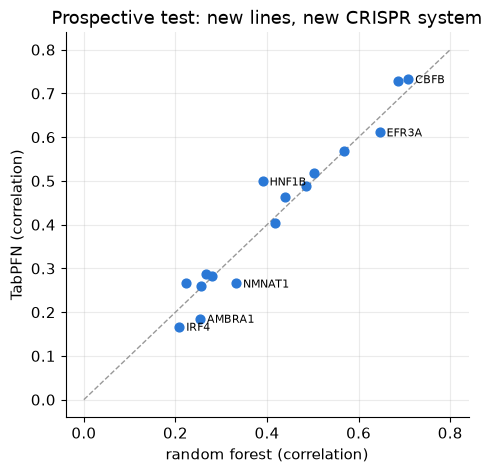

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 0.8], [0, 0.8], color="#999", lw=1, ls="--")
ax.scatter(pros["random forest"], pros["TabPFN (in-context)"], color=COLORS["TabPFN (in-context)"], s=40, zorder=3)
for (s, t), r in pros.iterrows():
    if t in ("HNF1B", "AMBRA1", "NMNAT1", "CBFB", "IRF4", "EFR3A"):   # label the genes discussed below
        ax.annotate(t, (r["random forest"], r["TabPFN (in-context)"]), xytext=(5, -3), textcoords="offset points", fontsize=8)
ax.set(xlabel="random forest (correlation)", ylabel="TabPFN (correlation)", title="Prospective test: new lines, new CRISPR system")
plt.show()

**What just happened.** On new cell lines, measured with a different CRISPR system, all methods lose accuracy: about 0.42 against about 0.59 for the same genes within one release. The ordering holds. TabPFN and random forest tie (+0.004), and both beat ridge (+0.04 for TabPFN). The points hug the diagonal: no gene where one method is dramatically better, except HNF1B, where TabPFN leads (0.50 vs 0.39).

## 7. What we can and can't claim

**We can claim:**
- A model pretrained only on synthetic tables, with **no training at all**, predicts real cancer gene dependencies as well as a random forest at every data size we tried, and in a prospective test on new cell lines. That's a genuine and useful property.
- It does **not** show the few-shot advantage we predicted. With 64 labelled lines, random forest was better.

**A reviewer would point out:**
- **TabPFN was run with 2 ensemble members, not its default of 8**, to fit a laptop CPU. That probably handicaps it, most at small sizes. Re-running with 8 is the obvious next check and would need a GPU or several hours.
- **These are the older v2 weights.** Newer TabPFN versions report better accuracy but need a licence token and are non-commercial.
- **One feature recipe:** 50 expression genes chosen by correlation. With 16 lines that selection is very noisy for every method, which may mask differences.
- **20 genes, one data split.** The intervals account for gene-to-gene variation, not for other splits.
- **Random forest wasn't tuned either.** Both got fixed, reasonable settings decided in advance, which is fair but not the best each could do.

## Recap

| Concept | What we saw |
|---|---|
| In-context learning at scale | TabPFN predicts from labelled rows in one pass, with no training |
| Fair comparison | Same features, same context lines, settings fixed in advance |
| Learning curve | All methods improve from r ≈ 0.2 at 16 lines to ≈ 0.5 at 618 |
| Pre-registered verdict | No few-shot advantage (H1 failed); ties random forest with full data and prospectively |
| New cancer type | 8 examples help only a little, for every method |
| Honest reporting | The failed prediction is the headline, with the reasons it might have failed |

## 8. Run it yourself

The DepMap files (about 1.6 GB) and TabPFN weights (44 MB) aren't in this repository. The steps are in `README.md`; then:

```bash
python -m icl_bio.study curve        # about 1 hour on a laptop CPU
python -m icl_bio.study lineage      # about 2 hours
python -m icl_bio.study prospective  # needs the DepMap 26Q3 files
```

## Try it yourself

1. Re-run the 16- and 64-line comparisons with `n_estimators=8` (the default). Does TabPFN close the gap to random forest?
2. Replace the correlation-selected features with lineage plus the top 50 principal components of expression. Which method benefits most?
3. Pick a gene where TabPFN won prospectively (HNF1B) and one where it lost (AMBRA1). Which expression features did each method rely on?